<span color="blue"> Projeto: Inteligência Artificial - 07J </span>
<h4> <bold> Previsão de Cancelamento de Clientes (Churn) no Setor de Telecomunicações utilizando Machine Learning </bold> </h4>

| Integrantes do grupo | RA| 
|:-------------------|:---------------:|
| Guilherme Soares  |  10428380 | 
| Isabella Sofia Martins   |  10420398  |        
| Lucas César Kato |  10419319  |

<h3 color="blue"> Síntese do Conteúdo: </h3> 
<p>Este arquivo contém a Análise Exploratória de Dados (EDA) e a fase de preparação de dados estruturados utilizando o dataset 'Telco Customer Churn'.  
As etapas incluem limpeza de dados, análise de variáveis, geração de gráficos para identificação de padrões de cancelamento e preparação com One-Hot Encoding. 
O Dicionário de dados esta presente na pasta 'docs' do repositório.</p>

In [ ]:
# Histórico de Alterações:
# 14/09/2026: Isabella Sofia Martins - carregamento dos dados brutos e tratamento inicial 
# 14/09/2026: Isabella Sofia Martins - criação das visualizações gráficas e matrizes de correlação
# 14/09/2026: Isabella Sofia Martins - aplicação de one-hot encoding e normalização
# 15/11/2026: Isabella Sofia Martins - inclusão do dicionário de dados + melhoria na explicação do dataset 
# 15/11/2026: Isabella Sofia Martins - modelos de Machine Learning (Random Forest + Regressão Logistica)
# 16/11/2026: Isabella Sofia Martins - explicação de como os modelos atuam nesse cenário.

<h3> Síntese do Conteúdo: </h3> 
<p>Este arquivo contém a Análise Exploratória de Dados (EDA) e a fase de preparação de dados estruturados utilizando o dataset 'Telco Customer Churn'.
As etapas incluem limpeza de dados, análise de variáveis, geração de gráficos para identificação de padrões de cancelamento e preparação com One-Hot Encoding. </p>


<h3> 1. Instalação e import de bibliotecas necessárias </h3> 
<p> execute uma linha por vez no bloco abaixo para realizar as instalações se não tiver as bibliotecas em seu ambiente - caso contrário, importe as bibliotecas no próximo bloco.</p>


In [ ]:
pip install matplotlib

In [ ]:
pip install seaborn

In [10]:
pip install scikit-learn

In [ ]:
pip install pandas

In [ ]:
pip install numpy

In [5]:
# importação das libs 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

import csv

<h3> 2. Limpeza e tratamento da base inicial </h3>

In [6]:
# 1. carregamento do arquivo substituindo as vírgulas por colunas
df = pd.read_csv('telecom_customers_churn.csv', sep=',', quoting=csv.QUOTE_NONE)

# 2. limpa as aspas que ficaram nos nomes das colunas e nos dados
df.columns = df.columns.str.replace('"', '')

# 3. tratamento da coluna TotalCharges: tem espaços em branco onde deveriam ser números
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True) #remove as linhas que ficaram vazias após a conversão

for coluna in df.columns:
    if df[coluna].dtype == 'object': #se a coluna for texto
        df[coluna] = df[coluna].str.replace('"', '')

# 4. visualizaçao do resultado (agora deve estar separado em 21 colunas perfeitamente)
print(f"Total de Linhas e Colunas: {df.shape}")
display(df.head())

Total de Linhas e Colunas: (7032, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<h3> 3. Analise Exploratória de Dados (EDA) </h3>

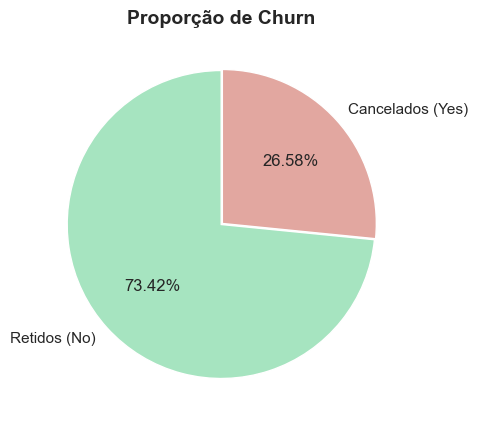

In [7]:
#config visual para os gráficos
sns.set_theme(style="whitegrid")

# Gráfico 1: Proporção total do Churn
plt.figure(figsize=(5, 5))
churn_counts = df['Churn'].value_counts()
plt.pie(churn_counts, labels=['Retidos (No)', 'Cancelados (Yes)'], autopct='%0.2f%%',  colors=["#a6e4c0", "#e2a7a0"], startangle=90, explode=(0, 0.01), shadow=False)
plt.title('Proporção de Churn', fontsize=14, fontweight='bold')
plt.savefig('grafico_01_proporcao_churn.png', bbox_inches='tight')
plt.show()

<h3> Grafico de Densidade (KDE): </h3>

<p> O modelo abaixo indica que os 5 primeiros meses são a zona crítica onde a operadora mais perde clientes. Campanhas de fidelização devem focar nesse período de integração (onboarding). </p>

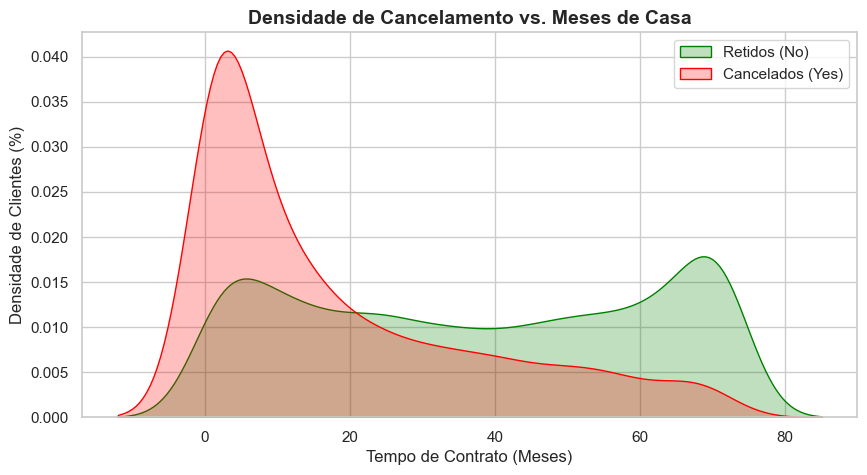

In [8]:
# Gráfico 2: Cancelamento vs. Tempo de Contrato (Tenure)
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df[df['Churn'] == 'No'], x='tenure', fill=True, color="green", label='Retidos (No)')
sns.kdeplot(data=df[df['Churn'] == 'Yes'], x='tenure', fill=True, color="red", label='Cancelados (Yes)')
plt.title('Densidade de Cancelamento vs. Meses de Casa', fontsize=14, fontweight='bold')
plt.xlabel('Tempo de Contrato (Meses)')
plt.ylabel('Densidade de Clientes (%)')
plt.legend()
plt.savefig('grafico_02_densidade_tempo.png', bbox_inches='tight')
plt.show()

<h3> Mensalidade vs. Tipo de Contrato </h3>
<p> Apesar de todas as modalidades de contrato possuirem maior evasão ao pagarem mensalidades mais caras, clientes no contrato mês a mês (month-to-month) e que pagam mensalidades altas concentram o maior volume absoluto de saída. Com isso, surge a forte hipótese da qualidade do produto fornecido a maior preço não apresentar um bom custo-benefício em relação aos planos básicos (mais baratos). </p>

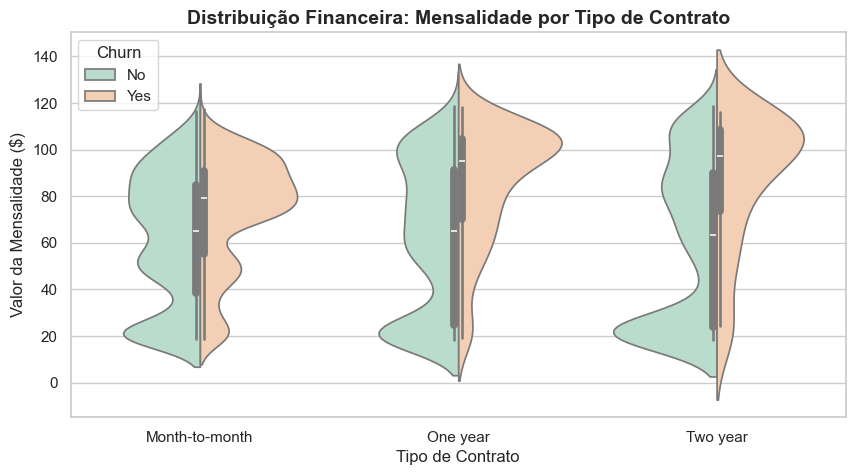

In [9]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x='Contract', y='MonthlyCharges', hue='Churn', split=True, palette='Pastel2')
plt.title('Distribuição Financeira: Mensalidade por Tipo de Contrato', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Valor da Mensalidade ($)')
plt.savefig('grafico_03_perfil_risco.png', bbox_inches='tight')
plt.show()

<h3> Cancelamentos por Tempo de Contrato </h3>

<p> No gráfico abaixo é possível concluir que a taxa de cancelamento é muito maior no plano mensal (desconsiderando custos entre planos de um mesmo ternure). </p>

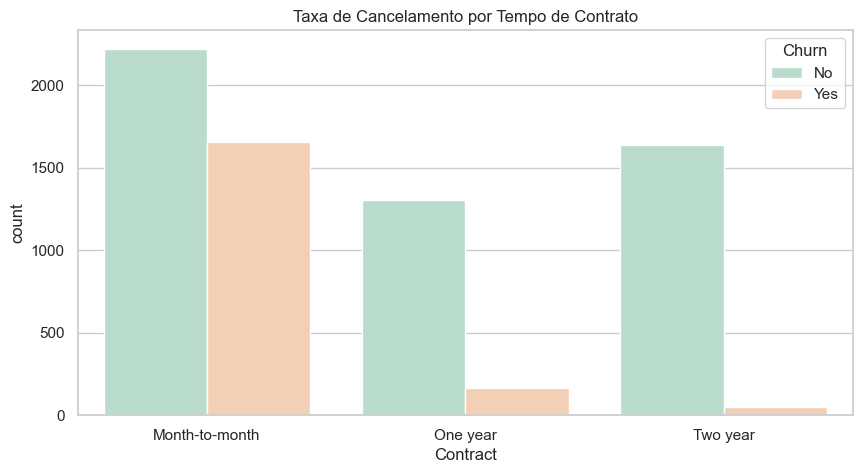

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Pastel2')
plt.title('Taxa de Cancelamento por Tempo de Contrato')
plt.savefig('grafico_04_contrato.png')
plt.show()

<h3> 4. Preparação da base para o modelo de Machine Learning </h3>

In [ ]:
# importação das bibliotecas de Machine Learning e Métricas
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, matthews_corrcoef, confusion_matrix

#### 1. carregamento e limpeza (Conforme definido na EDA)

In [37]:
# 1. carregamento e limpeza (Conforme definido na EDA)

df = pd.read_csv('telecom_customers_churn.csv', sep=',', quoting=csv.QUOTE_NONE)

# Limpa as aspas dos nomes das colunas
df.columns = df.columns.str.replace('"', '')

# Limpa as aspas dos dados em texto
for coluna in df.columns:
    if df[coluna].dtype == 'object':
        df[coluna] = df[coluna].str.replace('"', '')
display(df.head())

# Remove o ID do cliente pois não tem valor preditivo
df = df.drop('customerID', axis=1)

# Tratamento da coluna TotalCharges e remoção de nulos
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', ''), errors='coerce')
df = df.dropna()
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### preparacao para o machine learning

In [ ]:
# Separação das Variáveis (X e y)
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

# One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

# Divisão Treino e Teste (70/30 com proporção de churn mantida)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Normalização (Feita após o split para evitar vazamento de dados)
scaler = MinMaxScaler()
colunas_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_test[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

### Aplicação do modelo de Regressão Logística

A Regressão Logística tenta traçar uma reta que separa quem vai ficar de quem vai cancelar, através do calculo do peso matemático para cada coluna. Por exemplo: ela percebe que o contrato mensal (month-to-month) aumenta o risco, então dá um peso positivo alto para essa variável. Já o tempo de adesão (tenure) diminui o risco, ganhando um peso negativo.

No final, soma esses pesos para um novo cliente e retorna uma probabilidade de 0 a 100%. Se passar de 50%, ela classifica como "Vai Cancelar (1)". 

In [33]:
#3. MODELO BASELINE: REGRESSÃO LOGÍSTICA

print("DESEMPENHO DA REGRESSÃO LOGÍSTICA")
log_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)
print(classification_report(y_test, y_pred_log, target_names=['Retidos (0)', 'Cancelados (1)']))
print(f"MCC (Regressão Logística): {matthews_corrcoef(y_test, y_pred_log):.4f}\n")

DESEMPENHO DA REGRESSÃO LOGÍSTICA
                precision    recall  f1-score   support

   Retidos (0)       0.90      0.72      0.80      1549
Cancelados (1)       0.50      0.79      0.61       561

      accuracy                           0.73      2110
     macro avg       0.70      0.75      0.71      2110
  weighted avg       0.80      0.73      0.75      2110

MCC (Regressão Logística): 0.4506



#### Modelo Random Forest 
Para a execução deste algoritmo, são definidos parâmetros específicos (como n_estimators=100, que determina a construção de 100 árvores independentes).

Cada árvore de decisão atua como um fluxograma lógico e estruturado que avalia as características do cliente de forma sequencial. Na prática, a árvore aplica testes condicionais sucessivos - por exemplo: 
* Verifica se o tipo de contrato é mensal. 
* Se sim, avalia se a mensalidade ultrapassa os 70 dólares 
* Se sim, verifica se a permanência na empresa é inferior a cinco meses 
* Se sim, culmina na probabilidade de cancelamento (Churn).

Durante a fase de treino, o sistema gera estes 100 fluxogramas de forma distinta, alimentando cada um deles com subconjuntos aleatórios dos dados globais para garantir a diversidade da análise. Na fase de previsão, quando um novo cliente é submetido ao modelo, o seu perfil é avaliado por todas as árvores. A decisão final do algoritmo é apurada através de um mecanismo de votação maioritária: 
Se em um universo de 100 árvores, 60 preverem o cancelamento e 40 preverem a retenção, o modelo adota o veredicto da maioria e classifica o perfil com a indicação preditiva de "Vai Cancelar" (1). Essa abordagem baseada na agregação de múltiplos modelos (ensemble) confere ao Random Forest grande aptidão para captar regras altamente complexas e mapear padrões não lineares de comportamento.

In [32]:
# 4. MODELO AVANÇADO: RANDOM FOREST
print("DESEMPENHO DO MODELO RANDOM FOREST")
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=['Retidos (0)', 'Cancelados (1)']))
print(f"MCC (Random Forest): {matthews_corrcoef(y_test, y_pred_rf):.4f}")

DESEMPENHO DO MODELO RANDOM FOREST
                precision    recall  f1-score   support

   Retidos (0)       0.86      0.82      0.84      1549
Cancelados (1)       0.56      0.64      0.60       561

      accuracy                           0.77      2110
     macro avg       0.71      0.73      0.72      2110
  weighted avg       0.78      0.77      0.78      2110

MCC (Random Forest): 0.4400


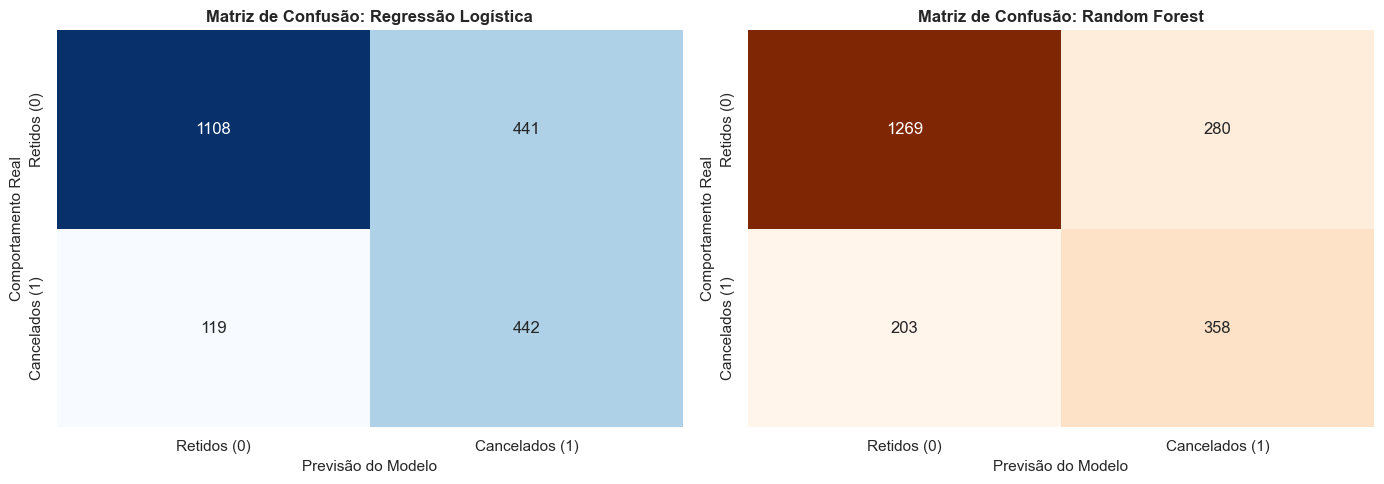

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Cálculo das Matrizes de Confusão
cm_log = confusion_matrix(y_test, y_pred_log)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# 2. Configuração da Figura (1 linha, 2 colunas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3. Gráfico 1: Regressão Logística
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retidos (0)', 'Cancelados (1)'],
            yticklabels=['Retidos (0)', 'Cancelados (1)'],
            cbar=False)
axes[0].set_title('Matriz de Confusão: Regressão Logística', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Previsão do Modelo', fontsize=11)
axes[0].set_ylabel('Comportamento Real', fontsize=11)

# 4. Gráfico 2: Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Retidos (0)', 'Cancelados (1)'],
            yticklabels=['Retidos (0)', 'Cancelados (1)'],
            cbar=False)
axes[1].set_title('Matriz de Confusão: Random Forest', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Previsão do Modelo', fontsize=11)
axes[1].set_ylabel('Comportamento Real', fontsize=11)

# Ajuste visual e exportação da imagem
plt.tight_layout()
plt.savefig('matriz_confusao_modelos.png', bbox_inches='tight', dpi=300)
plt.show()